# Modeled importance–latency distributions

Compare retained importance and additive two-line latency using the results from
[02_02](02_02_global_oracle.ipynb) and [02_03](02_03_selector_sweep.ipynb).
Global DP is the fixed-budget reference under this cost model.

In [3]:
from math import ceil
from matplotlib.lines import Line2D

import pandas            as pd
import matplotlib.pyplot as plt

## 1. Data

Budgets are requested row fractions. Global DP and Tiles select exactly $R$ rows;
Paper may select fewer. Use each method's recorded mask.

Latency is in ms. Retained importance is $100\sum_i v_iM_i/\sum_i v_i$,
where $v_i$ is the captured mean absolute activation.

In [4]:
reference = pd.read_csv("oracle_reference.csv", float_precision="round_trip")
selectors = pd.read_csv("selector_results.csv", float_precision="round_trip")

# concat two csv
results   = pd.concat([reference, selectors], ignore_index=True)

In [5]:
assert (results.importance_total > 0).all() and (results.latency > 0).all()

# importance
results["retained"] = 100 * results.importance / results.importance_total

## 2. Trace summaries

Each observation pairs latency and retained importance for one trace, method,
and requested budget. Within each shape, check that methods use the same traces
and budgets.

For each method and budget, compute the two marginal medians across traces.
Each trace has equal weight.

In [6]:
class TracePoints:
    def __init__(self, rows):

        # provided points 
        self.samples = (
            rows.set_index("trace_id")[["latency", "retained"]]
            .sort_index()
        )

        # median point
        self.median = self.samples.quantile(0.5)

In [7]:
class MethodResults:
    def __init__(self, rows):
        self.tile_width = rows.tile_width.iloc[0]
        self.budgets    = {}

        for fraction, group in rows.groupby("fraction"):
            self.budgets[fraction] = TracePoints(group)

    def median_curve(self):
        medians = {}

        for fraction, group in self.budgets.items():
            medians[fraction] = group.median

        return pd.DataFrame.from_dict(medians, orient="index")

    def assert_comparable_to(self, baseline):
        assert self.budgets.keys() == baseline.budgets.keys()

        for fraction, group in self.budgets.items():
            current_index  = group.samples.index
            baseline_index = baseline.budgets[fraction].samples.index

            assert current_index.equals(baseline_index)

In [8]:
class ShapeResults:
    def __init__(self, shape, rows):
        self.shape           = shape
        self.saturation_rows = rows.saturation_rows.iloc[0]
        self.trace_count     = rows.trace_id.nunique()
        self.methods         = {}

        groups = rows.groupby("method")

        widths = groups.tile_width.first()
        widths = widths.sort_values(
            ascending   = False,
            na_position = "first",
        )

        for name in widths.index:
            method_rows = groups.get_group(name)
            self.methods[name] = MethodResults(method_rows)

In [9]:
points = {}

for shape, rows in results.groupby(["n", "d"]):
    points[shape] = ShapeResults(shape, rows)

In [10]:
points[(896, 896)].methods["Global DP"].budgets[0.1].samples.head()

,latency,retained
trace_id,,
0,0.071766,13.551761
3,0.071766,16.210650
7,0.071766,11.376960
10,0.071766,17.149528
14,0.071766,11.905797


In [11]:
# Check matching fractions and trace IDs across methods.
for result in points.values():
    baseline = result.methods["Global DP"]

    for method in result.methods.values():
        method.assert_comparable_to(baseline)

## 3. Plot

Points show individual traces; color identifies the requested fraction.
Solid lines connect marginal medians in budget order. The dotted line shows
the Global DP reference. These summaries do not define a Pareto frontier.

Baseline/coarse and fine panels use separate logarithmic latency ranges
and a common importance range.

In [12]:
color_scale = plt.cm.ScalarMappable(
    norm = plt.Normalize(results.fraction.min(), results.fraction.max()), 
    cmap = "viridis",
)

def draw_observations(ax, method):
    for fraction, group in method.budgets.items():
        samples = group.samples
        ax.scatter(
            samples.latency, 
            samples.retained,
            color = color_scale.to_rgba(fraction), 
            s     = 9, 
            alpha = 0.16,
        )

def draw_median_curve(ax, method):
    curve = method.median_curve()
    ax.plot(
        curve.latency, 
        curve.retained, 
        color = "black"
    )
    ax.scatter(
        curve.latency, 
        curve.retained,
        c          = color_scale.to_rgba(curve.index), 
        edgecolors = "black", 
        zorder     = 3,
    )

def draw_method(ax, method, oracle=None):
    if oracle is not None:
        ax.plot(
            oracle.latency, 
            oracle.retained, 
            ":", 
            color = "gray"
        )

    draw_observations(ax, method)
    draw_median_curve(ax, method)

In [13]:
def draw_legend(fig):
    reference = Line2D(
        (), (),
        color     = "gray",
        linestyle = ":",
        label     = "Global DP median",
    )

    observations = Line2D(
        (), (),
        color      = "gray",
        linestyle  = "none",
        marker     = "o",
        markersize = 3,
        alpha      = 0.16,
        label      = "Trace observations",
    )

    medians = Line2D(
        (), (),
        color = "black",
        label = "Marginal medians",
    )

    fig.legend(
        handles = (reference, observations, medians),
        loc     = "outside lower center",
        ncol    = 3,
    )

In [14]:
def draw_shape(result):
    n, d    = result.shape
    s       = result.saturation_rows
    methods = result.methods
    oracle  = methods["Global DP"].median_curve()

    ncols = 4
    nrows = ceil(len(methods) / ncols)
    fig   = plt.figure(figsize=(4 * ncols, 3 * nrows), layout="constrained")
    
    shared_x = {}

    for position, (name, method) in enumerate(methods.items(), 1):
        B = method.tile_width

        # Prepare the panel title, axis group, and reference.
        if pd.isna(B):
            title = name
            axis_group = "baseline/coarse"
        elif B < s:
            title = f"{name}\nB = {B:g} (< s)"
            axis_group = "fine"
        else:
            title = f"{name}\nB = {B:g} (≥ s)"
            axis_group = "baseline/coarse"

        reference = None
        if name != "Global DP":
            reference = oracle

        # Create and draw the panel.
        ax = fig.add_subplot(
            nrows, ncols, position,
            sharex = shared_x.get(axis_group),
        )
        shared_x[axis_group] = ax

        draw_method(
            ax, method,
            oracle = reference,
        )
        ax.set(
            title  = title,
            xscale = "log",
            ylim   = (0, 102),
            xlabel = "Modeled latency (ms)",
        )

    # Shared guides for the whole figure.
    draw_legend(fig)
    fig.colorbar(color_scale, ax=fig.axes, label="Requested fraction")
    fig.supylabel("Retained importance (%)")

    title = f"{n} x {d} · {result.trace_count} traces · s = {s:.2f} rows"
    subtitle = "Baseline/coarse and fine panels use separate log-latency ranges"
    fig.suptitle(f"{title}\n{subtitle}")
    return fig

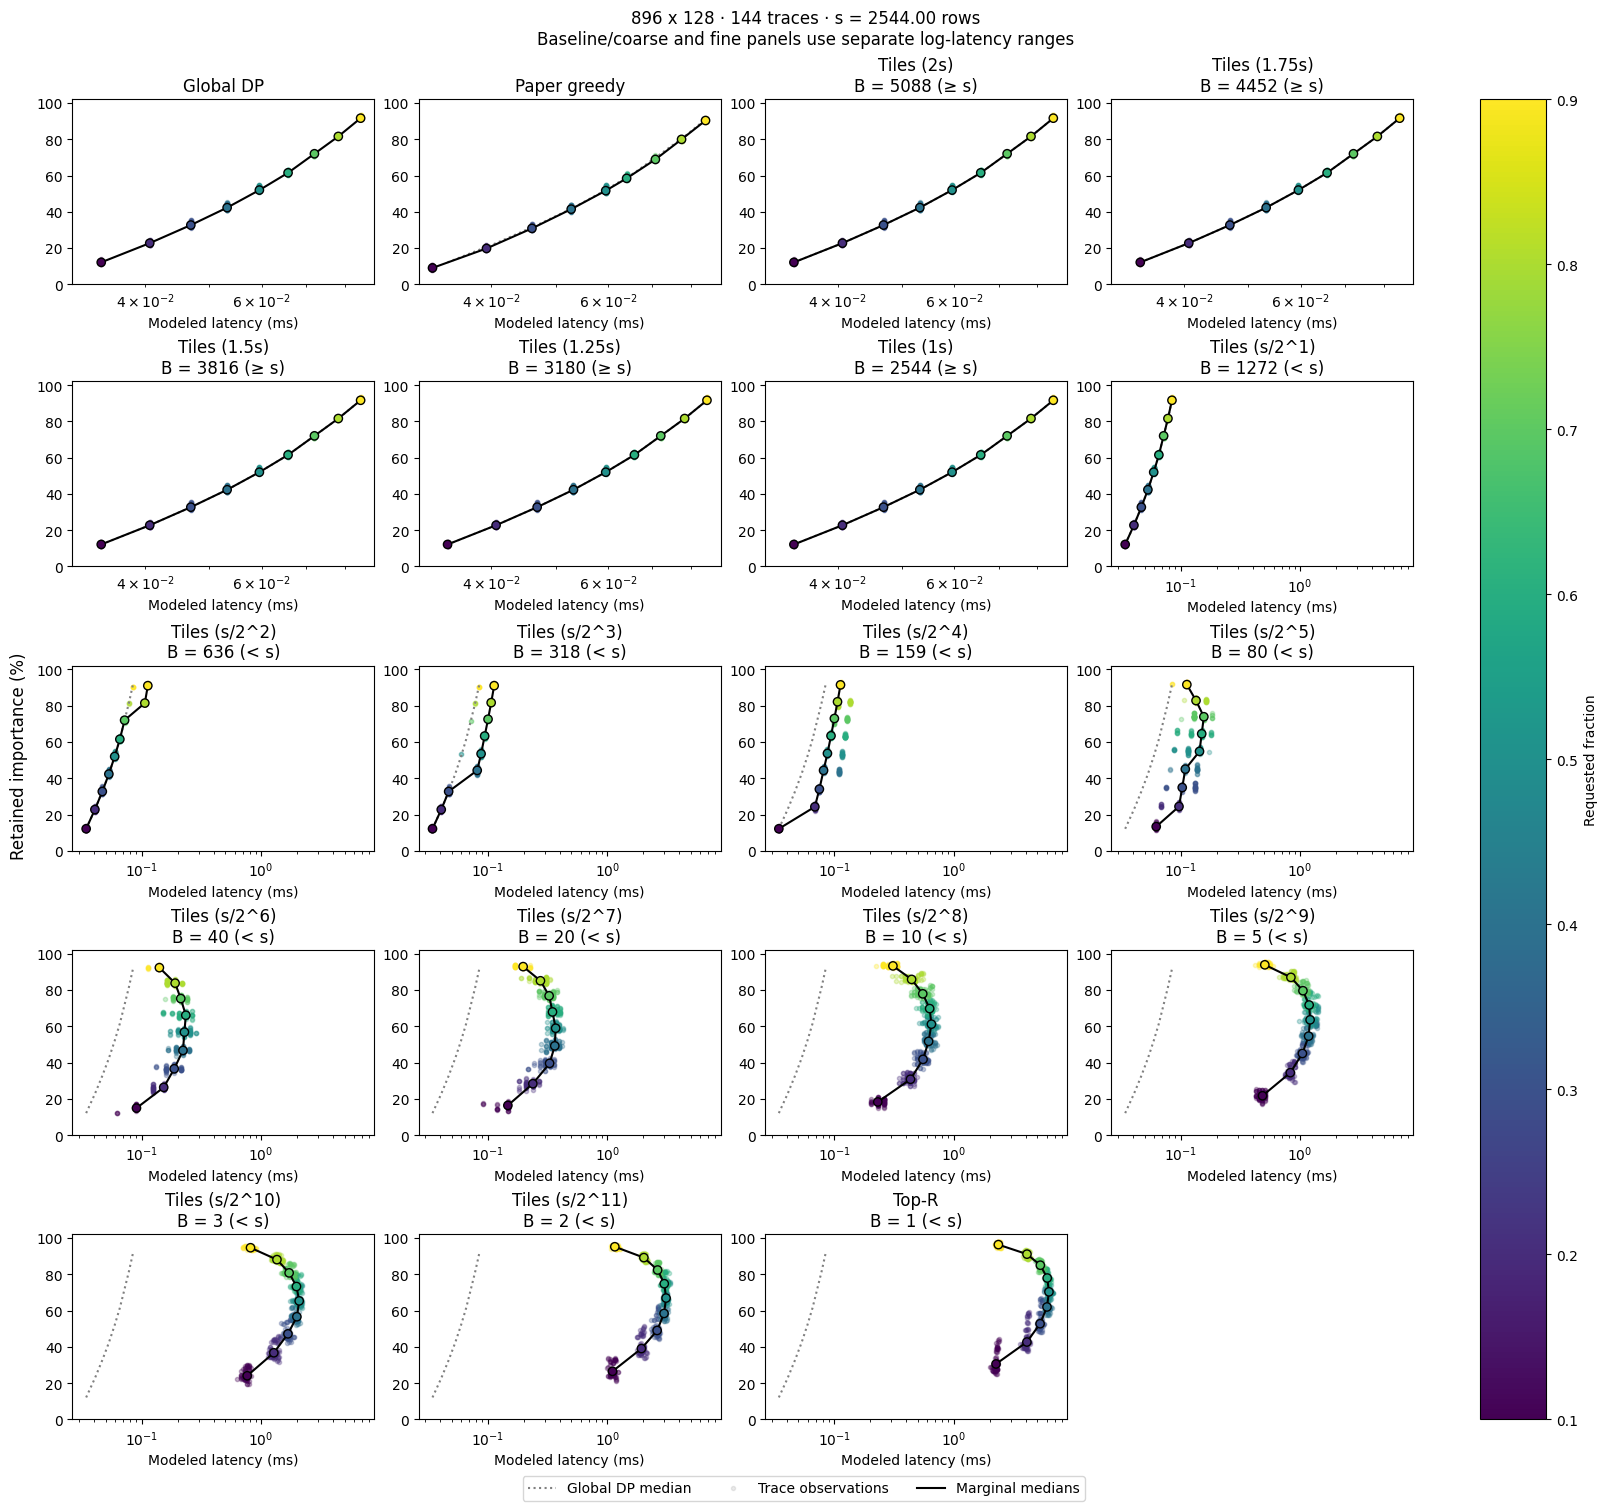

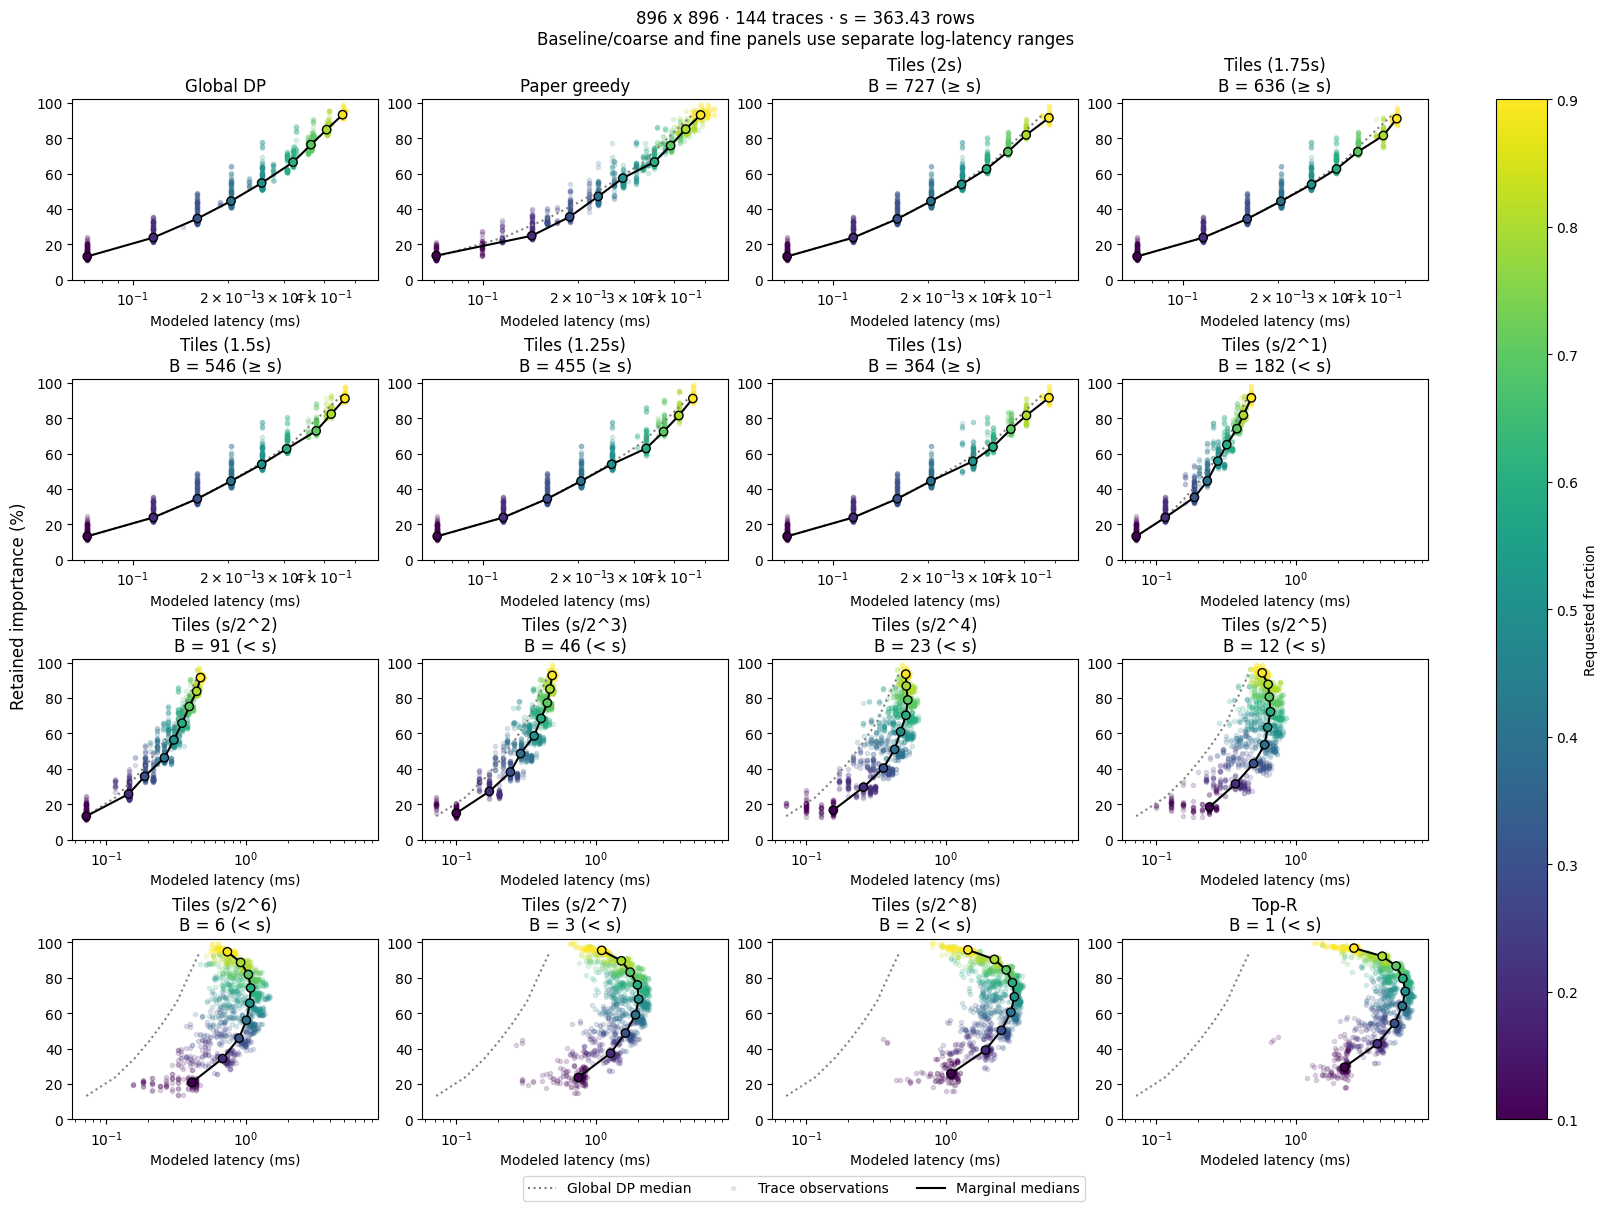

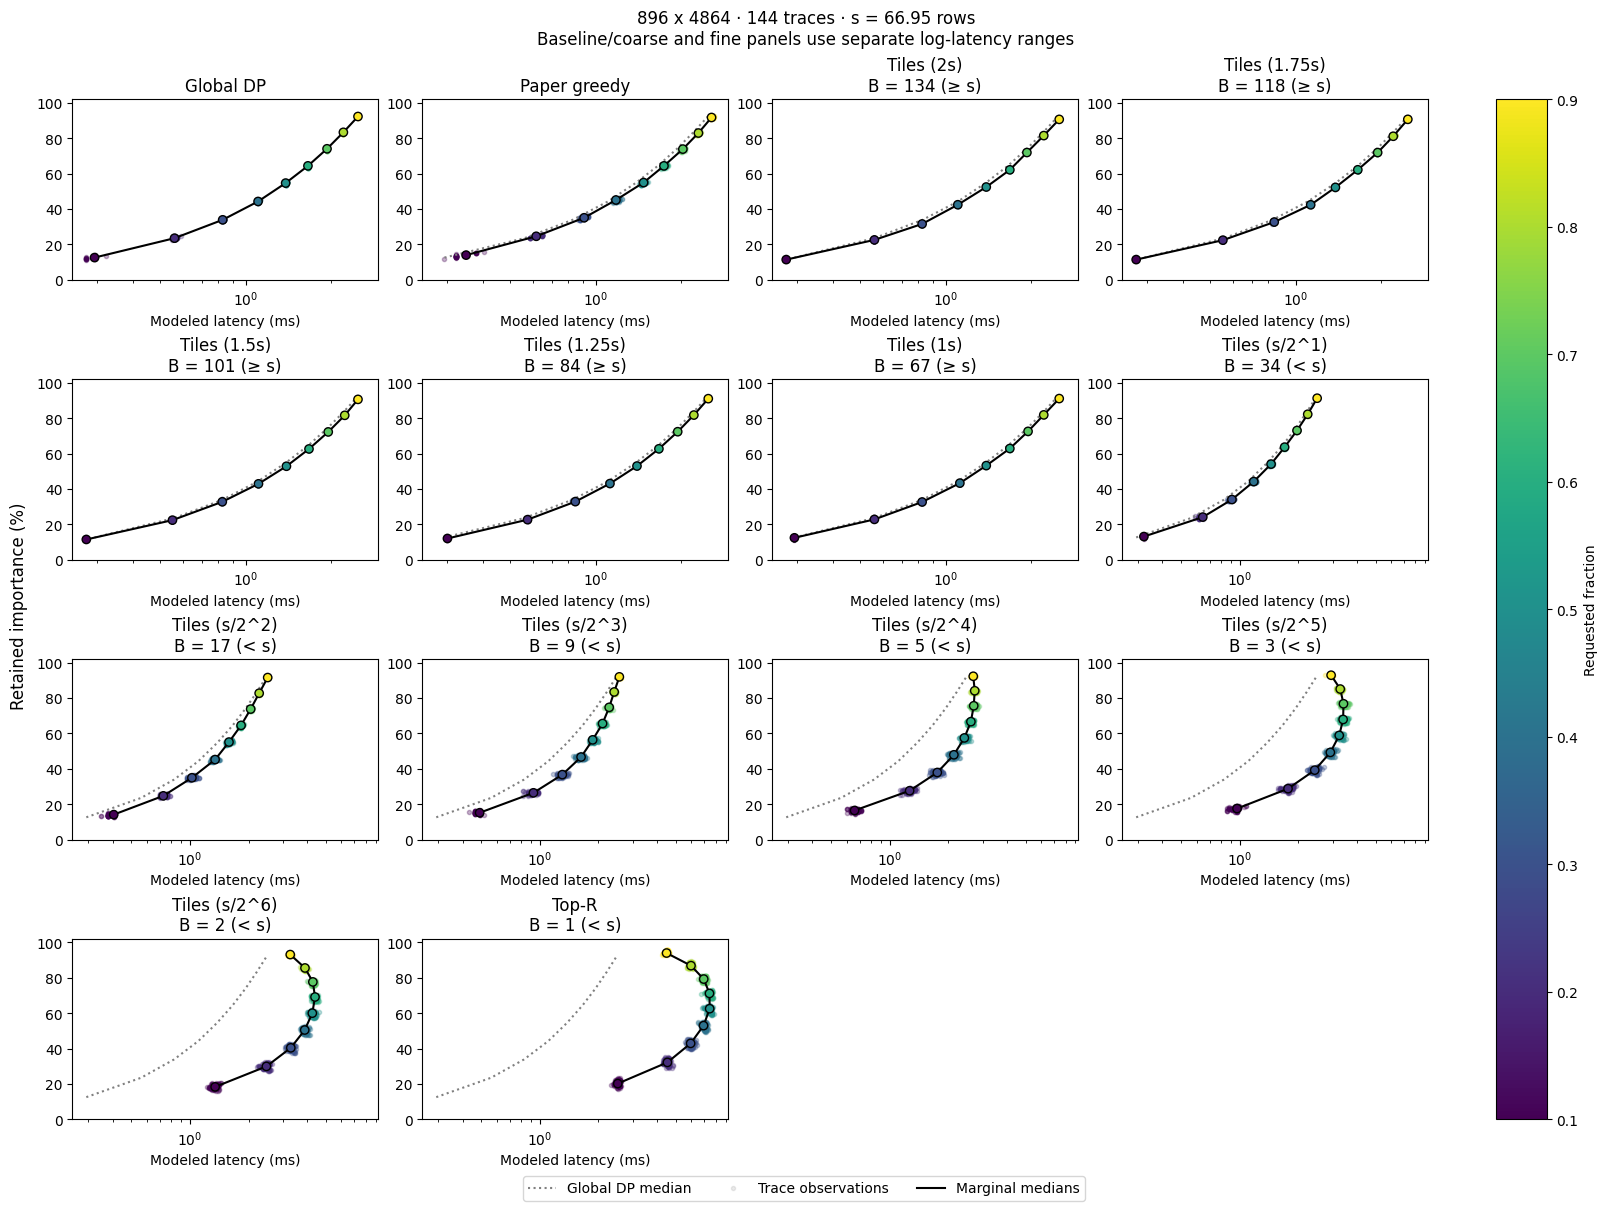

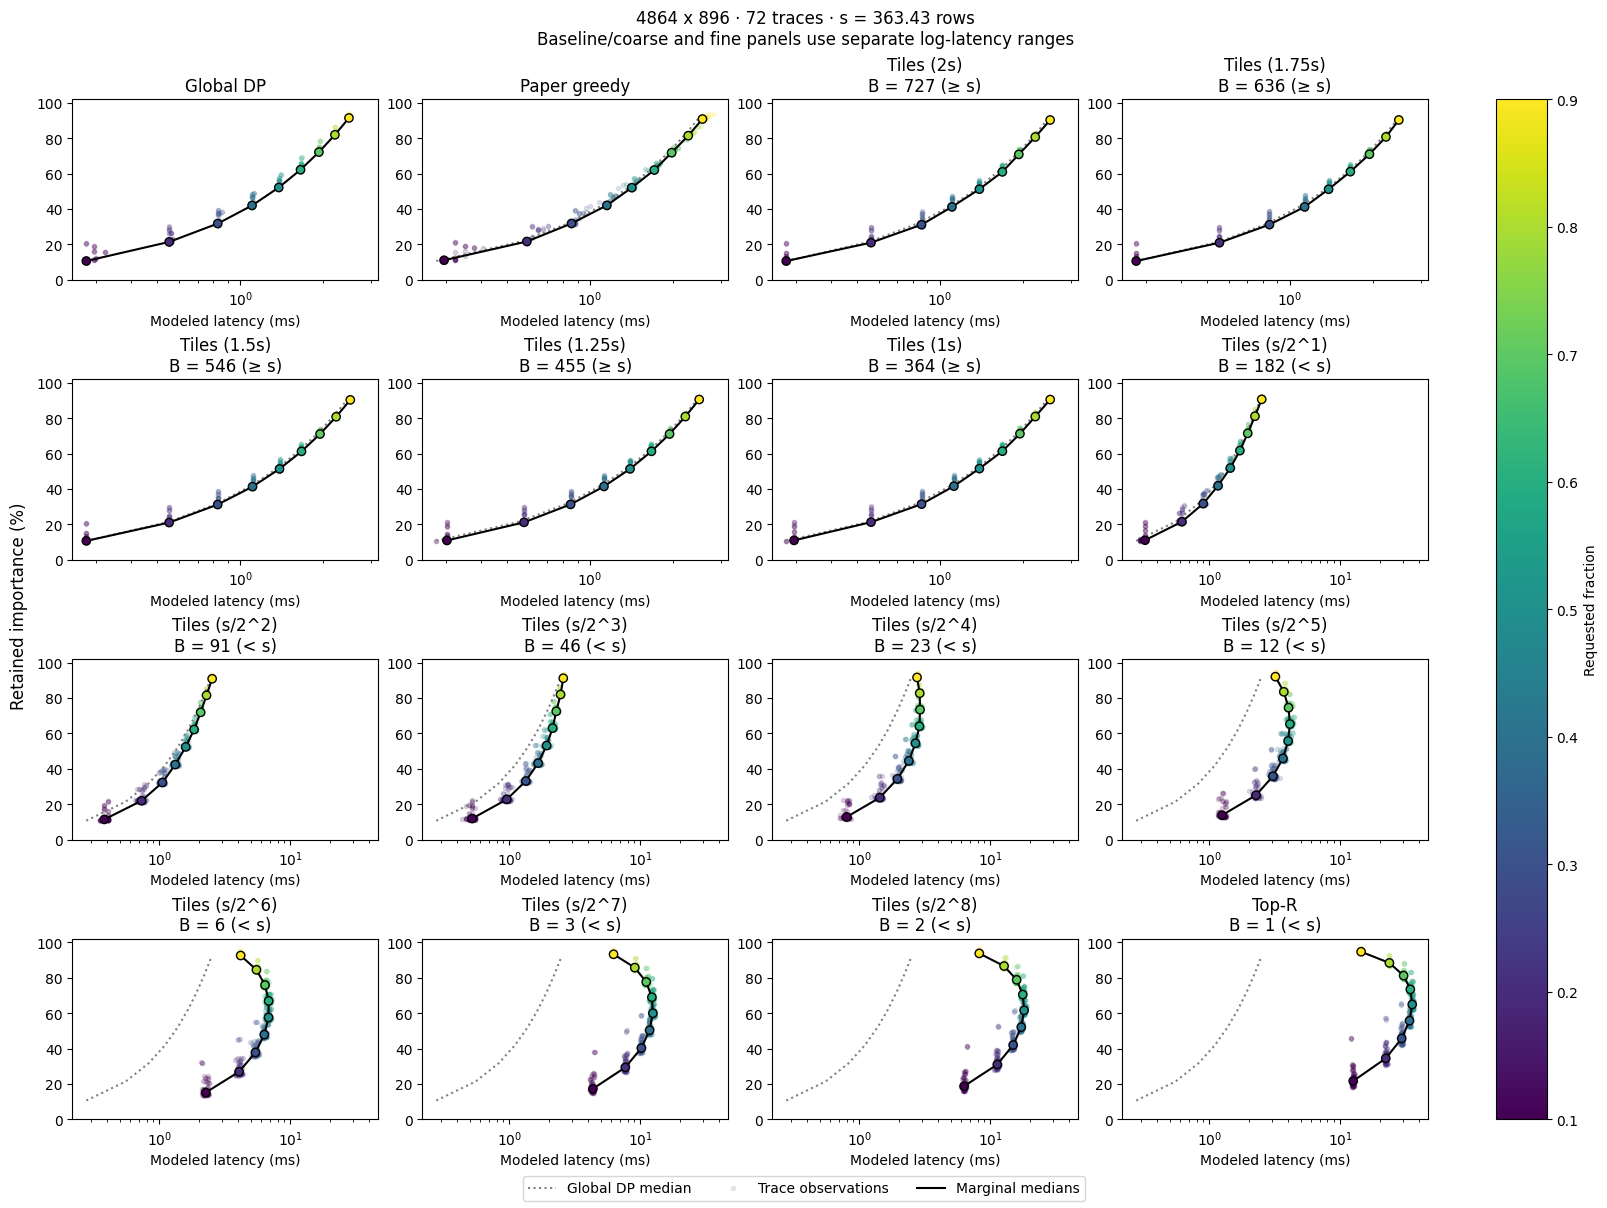

In [15]:
for result in points.values():
    fig = draw_shape(result)

    plt.show()
    plt.close(fig)